In [1]:
import torch 
import torch.nn as nn
import math
import typing
from typing import List, Union
import pandas as pd
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt

In [2]:
def interpretar_predicoes(x: torch.Tensor, y: torch.Tensor, id_to_text: dict):
    """
    Converte as predições do modelo e os targets reais em formato de texto.
    
    Args:
        x (torch.Tensor): Tensor de logits ou probabilidades, shape (batch_size, vocab_size)
        y (torch.Tensor): Tensor de rótulos reais, shape (batch_size,)
        id_to_text (dict): Dicionário que mapeia IDs para texto.

    Returns:
        list: Lista de strings com a previsão e o target correspondente.
    """
    # Obtém os índices das palavras mais prováveis
    pred_ids = torch.argmax(x, dim=-1)  # Obtém o índice da maior probabilidade

    resultados = []
    for pred_id, target_id in zip(pred_ids.tolist(), y.tolist()):
        pred_text = id_to_text.get(pred_id, "[UNK]")  # Retorna "[UNK]" se ID não estiver no dicionário
        target_text = id_to_text.get(target_id, "[UNK]")
        resultados.append(f"Predição: {pred_text} | Target: {target_text}")

    return resultados

In [3]:
def split_train_test(tensor: torch.Tensor, train_percent: float, random:bool=False):
    """
    Divide um tensor em treino e teste, garantindo que os índices sejam inteiros.
    """
    if random:
        assert isinstance(train_percent, float), "train_percent deve ser um número decimal entre 0 e 1."
        assert 0.0 < train_percent < 1.0, "O percentual de treino deve estar entre 0 e 1."

        num_train = int(round(len(tensor) * train_percent))  # Conversão segura para inteiro

        indices = torch.randperm(len(tensor))  # Embaralha os índices
        train_indices, test_indices = indices[:num_train], indices[num_train:]  # Separa treino e teste

        return tensor[train_indices], tensor[test_indices]
    else:
        return tensor[:int(len(tensor)*train_percent)], tensor[int(len(tensor)*train_percent):]

def custom_dataloader(dataset, batch_size, context_len, device):
    dataset_size = len(dataset)
    max_iter = dataset_size // batch_size

    def generator():
        for _ in range(max_iter): 
            # Gere n índices aleatórios no intervalo permitido
            ix = torch.randint(0, dataset_size - context_len, (batch_size,))
            
            # xb são as sequências de entrada (context_len tokens)
            x = torch.stack([dataset[i:i+context_len] for i in ix])

            # yb são os próximos tokens (o próximo token de cada sequência de xb)
            y = torch.stack([dataset[i+1:i+context_len+1] for i in ix])

            yield x, y
        
    return generator()


def one_hot_encoding(token_ids: torch.Tensor, vocab_size: int):
    """
    Cria uma matriz de one-hot encoding para múltiplos token_ids.

    Args:
        token_ids (torch.Tensor): Tensor 1D contendo os índices dos tokens a serem marcados com 1.
        vocab_size (int): Número total de posições possíveis.

    Returns:
        torch.Tensor: Matriz de shape (len(token_ids), vocab_size) onde cada linha é um vetor one-hot.
    """
    batch_size = token_ids.shape[0]
    one_hot_matrix = torch.zeros((batch_size, vocab_size), dtype=torch.float32)
    one_hot_matrix[torch.arange(batch_size), token_ids] = 1.0  # Define 1 nas posições dos token_ids
    return one_hot_matrix

class PositionStateTokenizer(nn.Module):
    def __init__(self, positions: List[str], vocab_size:int) -> None:
        super().__init__()
        self.positions = positions.copy()
        assert vocab_size == len(set(positions))
        self.vocab_size = len(set(positions))
        self.string_to_id = {p:i for i, p in enumerate(positions)}
        self.id_to_string = {i:p for i, p in enumerate(positions)}

    def forward(self, x: List[str], get_tensor: bool=True) -> Union[torch.tensor, list]:
        if get_tensor:
            return torch.tensor([self.string_to_id[p] for p in x], dtype=torch.long)
        else:
            return [self.string_to_id[p] for p in x]
    def reverse(self, x: List[int]) -> list:
        return [self.id_to_string[i] for i in x]

class InputEmbeddings(nn.Module):
    def __init__(self, vocab_size: int, d_model:int,) -> None:
        super().__init__()
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=d_model)
    def forward(self, x):
        return self.embedding(x) * math.sqrt(self.d_model)
    
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_seq_length: int) -> None:
        super().__init__()
        self.d_model = d_model
        self.max_seq_length = max_seq_length

        pe = torch.zeros(max_seq_length, d_model)
        position = torch.arange(0, max_seq_length, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float) * -(math.log(10_000)/d_model))

        pe[:, 0::2] = torch.sin(position * div_term) # even positions
        pe[:, 1::2] = torch.cos(position * div_term) # odd positions

        self.register_buffer('pe', pe.unsqueeze(0))
    
    def forward(self, x:torch.tensor) -> torch.tensor:
        return x + self.pe[:, :x.size(1)]
    
class AttentionHead(nn.Module):
    def __init__(self, head_dim: int) -> None:
        super().__init__()
        self.head_dim = head_dim

        self.key = nn.Linear(head_dim, head_dim, bias=False)
        self.query = nn.Linear(head_dim, head_dim, bias=False)
        self.value = nn.Linear(head_dim, head_dim, bias=False)

    def forward(self, q, k, v, mask=None):
        attention_scores = (q @ k.transpose(-2, -1)) / (self.head_dim ** 0.5)

        if mask is not None:
            attention_scores = attention_scores.masked_fill(mask == 0, float('-inf'))
        
        attention_weights = F.softmax(attention_scores, dim=-1)
        output = attention_weights @ v
        return output

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int) -> None:
        super().__init__()
        assert d_model % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        self.key = nn.Linear(d_model, d_model, bias=False)
        self.query = nn.Linear(d_model, d_model, bias=False)
        self.value = nn.Linear(d_model, d_model, bias=False)

        self.heads = nn.ModuleList([AttentionHead(self.head_dim) for _ in range(num_heads)])
        self.output_layer = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x, mask=None):
        batch_size, seq_length, _ = x.shape

        k = self.key(x).view(batch_size, seq_length, self.num_heads, self.head_dim).transpose(1, 2)
        q = self.query(x).view(batch_size, seq_length, self.num_heads, self.head_dim).transpose(1, 2)
        v = self.value(x).view(batch_size, seq_length, self.num_heads, self.head_dim).transpose(1, 2)

        head_outputs = [h(q[:, i, :, :], k[:, i, :, :], v[:, i, :, :], mask) for i, h in enumerate(self.heads)]  # 🔥 Corrigido
        output = torch.cat(head_outputs, dim=-1)

        output = self.output_layer(output)
        return output

class FeedForwardLayer(nn.Module):
    def __init__(self, d_model: int, d_ff: int ) -> None:
        super().__init__()
        self.d_model = d_model
        self.d_ff = d_ff
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.activation_layer = nn.ReLU()
    
    def forward(self, x) -> torch.tensor:
        x = self.linear1(x)
        x = self.activation_layer(x)
        x = self.linear2(x)
        return x

class DecoderTransformerBody(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int, context_len: int, dropout: float):
        super().__init__()
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_ff = d_ff
        self.context_len = context_len
        self.dropout = nn.Dropout(dropout)
        self.norm_layer1 = nn.LayerNorm(normalized_shape=d_model)
        self.norm_layer2 = nn.LayerNorm(normalized_shape=d_model)
        self.mhsa = MultiHeadAttention(d_model=d_model, num_heads=num_heads)
        self.ffwd = FeedForwardLayer(d_model=d_model, d_ff=d_ff)

        # tril
        self.register_buffer('tril', torch.tril(torch.ones(self.context_len, self.context_len)))

    def forward(self, x) -> torch.tensor:
        # decoder mask 
        mask = self.tril[:self.context_len, :self.context_len]

        # sublayer mhsa
        att_weigths = self.mhsa(x, mask)
        
        att_weigths = x + att_weigths
        att_weigths = self.norm_layer1(att_weigths)
        # att_weigths = self.dropout(att_weigths)

        out = att_weigths + self.ffwd(att_weigths)

        out = self.norm_layer2(out)
        # out = self.dropout(out)

        return out
    
class DecoderTransformerHead(nn.Module):
    def __init__(self, d_model: int, vocab_size: int):
        super().__init__()
        self.d_model = d_model
        self.vocab_size = vocab_size
        self.linear_vocab = nn.Linear(d_model, vocab_size)

    def forward(self, x, generate) -> torch.tensor:
        x = self.linear_vocab(x) # logits
        if generate:
            return F.softmax(x, dim=-1)
        else:
            return x

class DecoderTransformer(nn.Module):
    def __init__(self
                 , blocks: int
                 , d_model: int
                 , num_heads: int
                 , d_ff: int
                 , context_len: int
                 , dropout:float
                 , vocab_size: int):
        super().__init__()
        self.blocks = blocks
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_ff = d_ff
        self.context_len = context_len
        self.dropout = dropout
        self.vocab_size = vocab_size
        # toekn embedding
        self.embedding = InputEmbeddings(
            vocab_size=vocab_size, d_model=d_model
        )
        # positional encoding
        self.pos_enc = PositionalEncoding(
            d_model=d_model, max_seq_length=context_len
        )
        # net architecture
        self.decoder_blocks = nn.ModuleList([DecoderTransformerBody(
            d_model=self.d_model,
            num_heads=self.num_heads,
            d_ff=self.d_ff,
            context_len=self.context_len,
            dropout=self.dropout
        ) for _ in range(self.blocks)])

        self.net = nn.Sequential(*self.decoder_blocks)
        self.decoder_head = DecoderTransformerHead(d_model=self.d_model, vocab_size=self.vocab_size)

    def forward(self, x, generate: bool):
        x = self.embedding(x)
        x = self.pos_enc(x)
        
        for block in self.decoder_blocks:
            x = block(x)  # 🔥 Corrigido
        
        out = self.decoder_head(x, generate)
        return out

In [4]:
df = pd.read_csv(r'df_trainset_v0.csv')
print(df.shape)
df.head(2)

(8690, 12)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,encode_position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.05,"[0.9481359873429684, 0.33197961175786933]",0.002769,"[0.05478942838579304, -0.008028506825109583]",-2.588245,"[0.998248480520846, -0.05916055390056853]",JUSISZHZYBKOLQVLLOCAAJECMBKL,[[0.75863461 0.78054116 0.05602303 0.7335959 ...,2043,0.412311,NaN,1
1,0.55,"[0.9583626153133962, 0.31473816173083613]",0.029473,"[-0.037931302661557975, -0.04846669295025419]",-6.319246,"[-0.06967333450757067, -0.9975698604401579]",JUSISZHZYBKOLOCALQVLAJECMBKL,[[0.75863461 0.78054116 0.05602303 0.12314067 ...,2035,0.410696,2043.0,1


In [5]:
positions = df['position_state'].values
unique_positions = df['position_state'].unique()

len(positions), len(unique_positions)

(8690, 4955)

In [6]:
id_to_pos_dict = {k:v for k, v in df[['position_state_id', 'position_state']].values}
pos_to_id_dict = {v:k for k, v in df[['position_state_id', 'position_state']].values}

In [7]:
# PARAMETERS
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device: ', DEVICE)
VOCAB_SIZE = df['position_state_id'].nunique()
D_MODEL = 32
MAX_SEQ_LEN = 16
NUM_HEADS = 2
D_FF = D_MODEL
DROPOUT = 0.9
NUM_DECODER_BLOCKS = 1
BATCH_SIZE = 512
NUM_EPOCHS = 1e3
LEARNING_RATE = 1e-4

device:  cuda


In [8]:
model = DecoderTransformer(
        blocks=NUM_DECODER_BLOCKS,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        d_ff=D_FF,
        context_len=MAX_SEQ_LEN,
        dropout=DROPOUT,
        vocab_size=VOCAB_SIZE
    )

In [9]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
loss_func = nn.CrossEntropyLoss()

In [10]:
dataset_tensor = torch.tensor(df['position_state_id'].values, dtype=torch.long)
# dataset_val = dataset_tensor[int(0.9*len(dataset_tensor)):]
# dataset_tensor = dataset_tensor[:int(0.9*len(dataset_tensor))]

# print(len(dataset_tensor), len(dataset_val))

In [11]:
train_tensor, test_tensor = split_train_test(dataset_tensor, 0.85, random=False)  # 80% treino, 20% teste

print(f"Tamanho do treino: {train_tensor.shape[0]}")
print(f"Tamanho do teste: {test_tensor.shape[0]}")

Tamanho do treino: 7386
Tamanho do teste: 1304


In [12]:
model.to(DEVICE)

DecoderTransformer(
  (embedding): InputEmbeddings(
    (embedding): Embedding(4955, 32)
  )
  (pos_enc): PositionalEncoding()
  (decoder_blocks): ModuleList(
    (0): DecoderTransformerBody(
      (dropout): Dropout(p=0.9, inplace=False)
      (norm_layer1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
      (norm_layer2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
      (mhsa): MultiHeadAttention(
        (key): Linear(in_features=32, out_features=32, bias=False)
        (query): Linear(in_features=32, out_features=32, bias=False)
        (value): Linear(in_features=32, out_features=32, bias=False)
        (heads): ModuleList(
          (0-1): 2 x AttentionHead(
            (key): Linear(in_features=16, out_features=16, bias=False)
            (query): Linear(in_features=16, out_features=16, bias=False)
            (value): Linear(in_features=16, out_features=16, bias=False)
          )
        )
        (output_layer): Linear(in_features=32, out_features=32, bias=F

In [13]:
loss_list = []
loss_list_val = []
for epoch in range(int(NUM_EPOCHS)):
    model.train()
    epoch_loss = 0
    counter = 1
    dataloader = custom_dataloader(
                    dataset = train_tensor
                    ,batch_size = BATCH_SIZE
                    ,context_len = MAX_SEQ_LEN
                    , device = DEVICE
                    )
    epoch_loss_list = []
    

    for xb, yb in dataloader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        predictions = model(xb, generate=False)
        loss = loss_func(predictions.view(-1, VOCAB_SIZE), yb.view(-1)) #loss_func(predictions.view(BATCH_SIZE*MAX_SEQ_LEN, VOCAB_SIZE), yb.view(BATCH_SIZE*MAX_SEQ_LEN))
        epoch_loss_list.append(loss.detach().cpu().numpy())
        loss.backward()
        optimizer.step()
    # if epoch%(NUM_EPOCHS/10)==0:
    loss_list.append(np.mean(epoch_loss_list))
    val_dataloader = custom_dataloader(
                dataset = test_tensor
                ,batch_size = BATCH_SIZE
                ,context_len = MAX_SEQ_LEN
                , device = DEVICE
                )
    model.eval()
    val_loss_list = []
    with torch.no_grad():
        for xbt, ybt in val_dataloader:
            xbt, ybt = xbt.to(DEVICE), ybt.to(DEVICE)
            val_predictions = model(xbt, generate=False)
            val_loss = loss_func(val_predictions.view(-1, VOCAB_SIZE), ybt.view(-1)) #loss_func(val_predictions.view(BATCH_SIZE*MAX_SEQ_LEN, VOCAB_SIZE), ybt.view(BATCH_SIZE*MAX_SEQ_LEN))
            val_loss_list.append(val_loss.detach().cpu().numpy())
    loss_list_val.append(np.mean(val_loss_list))
    if epoch%(NUM_EPOCHS/10) == 0:
        print(f"iter. {epoch} - loss = {np.mean(epoch_loss_list):4f} +- {np.std(epoch_loss_list):4f} [TEST: {np.mean(val_loss_list):4f}]", datetime.now())


iter. 0 - loss = 8.668737 +- 0.011301 [TEST: 8.682940] 2025-04-11 15:34:46.498172
iter. 100 - loss = 5.942363 +- 0.015187 [TEST: 9.028555] 2025-04-11 15:35:07.494133
iter. 200 - loss = 3.231733 +- 0.018326 [TEST: 9.609079] 2025-04-11 15:35:31.119204
iter. 300 - loss = 1.460189 +- 0.015242 [TEST: 10.429203] 2025-04-11 15:35:51.173404
iter. 400 - loss = 0.723692 +- 0.010153 [TEST: 11.580860] 2025-04-11 15:36:10.511013
iter. 500 - loss = 0.434121 +- 0.007359 [TEST: 12.506442] 2025-04-11 15:36:29.156307
iter. 600 - loss = 0.295824 +- 0.003892 [TEST: 13.235167] 2025-04-11 15:36:47.814413
iter. 700 - loss = 0.218848 +- 0.003851 [TEST: 13.904530] 2025-04-11 15:37:06.794081
iter. 800 - loss = 0.177243 +- 0.007277 [TEST: 14.713229] 2025-04-11 15:37:26.130233
iter. 900 - loss = 0.147732 +- 0.004614 [TEST: 15.540806] 2025-04-11 15:37:45.296289


In [ ]:
# class DecoderOnlyTransformer(nn.Module):
#     def __init__(self, vocab_size, d_model, num_heads, num_layers, d_ff, dropout, max_seq_len):
#         super().__init__()
#         self.embedding = nn.Embedding(vocab_size, d_model)
#         self.positional_encoding = nn.Parameter(torch.randn(1, max_seq_len, d_model))

#         decoder_layer = nn.TransformerDecoderLayer(
#             d_model=d_model, 
#             nhead=num_heads, 
#             dim_feedforward=d_ff, 
#             dropout=dropout, 
#             batch_first=True
#         )

#         self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_layers)
#         self.layer_norm = nn.LayerNorm(d_model)  # Added Layer Normalization
#         self.dropout = nn.Dropout(dropout)  # Dropout layer
#         self.output_layer = nn.Linear(d_model, vocab_size)

#     def forward(self, x):
#         seq_len = x.size(1)
#         x = self.embedding(x) + self.positional_encoding[:, :seq_len, :]
#         x = self.layer_norm(x)  # Apply LayerNorm
#         x = self.dropout(x)  # Apply Dropout

#         tgt_mask = self.generate_square_subsequent_mask(seq_len).to(x.device)
#         x = self.decoder(x, x, tgt_mask=tgt_mask)  # No encoder, so memory = x
        
#         x = self.output_layer(x)  # Compute final predictions
#         x = x + self.dropout(x)  # Apply residual connection properly
#         x = self.layer_norm(x)  # Apply LayerNorm after residual connection

#         return x

#     def generate_square_subsequent_mask(self, size):
#         return torch.triu(torch.ones(size, size), diagonal=1).masked_fill(torch.triu(torch.ones(size, size), diagonal=1) == 1, float('-inf'))


In [ ]:
# NUM_DECODER_LAYERS = 3

In [ ]:

# model = DecoderOnlyTransformer(VOCAB_SIZE, D_MODEL, NUM_HEADS, NUM_DECODER_LAYERS, D_FF, DROPOUT, MAX_SEQ_LEN)

In [14]:
# model.to(DEVICE)

In [ ]:
loss_list = []
loss_list_val = []
for epoch in range(int(NUM_EPOCHS)):
    model.train()
    epoch_loss = 0
    counter = 1
    dataloader = custom_dataloader(
                    dataset = train_tensor
                    ,batch_size = BATCH_SIZE
                    ,context_len = MAX_SEQ_LEN
                    , device = DEVICE
                    )
    epoch_loss_list = []
    

    for xb, yb in dataloader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        predictions = model(xb)
        loss = loss_func(predictions.view(-1, VOCAB_SIZE), yb.view(-1)) #loss_func(predictions.view(BATCH_SIZE*MAX_SEQ_LEN, VOCAB_SIZE), yb.view(BATCH_SIZE*MAX_SEQ_LEN))
        epoch_loss_list.append(loss.detach().cpu().numpy())
        loss.backward()
        optimizer.step()
    # if epoch%(NUM_EPOCHS/10)==0:
    loss_list.append(np.mean(epoch_loss_list))
    val_dataloader = custom_dataloader(
                dataset = test_tensor
                ,batch_size = BATCH_SIZE
                ,context_len = MAX_SEQ_LEN
                , device = DEVICE
                )
    model.eval()
    val_loss_list = []
    with torch.no_grad():
        for xbt, ybt in val_dataloader:
            xbt, ybt = xbt.to(DEVICE), ybt.to(DEVICE)
            val_predictions = model(xbt)
            val_loss = loss_func(val_predictions.view(-1, VOCAB_SIZE), ybt.view(-1)) #loss_func(val_predictions.view(BATCH_SIZE*MAX_SEQ_LEN, VOCAB_SIZE), ybt.view(BATCH_SIZE*MAX_SEQ_LEN))
            val_loss_list.append(val_loss.detach().cpu().numpy())
    loss_list_val.append(np.mean(val_loss_list))
    if epoch%(NUM_EPOCHS/10) == 0:
        print(f"iter. {epoch} - loss = {np.mean(epoch_loss_list):4f} +- {np.std(epoch_loss_list):4f} [TEST: {np.mean(val_loss_list):4f}]", datetime.now())


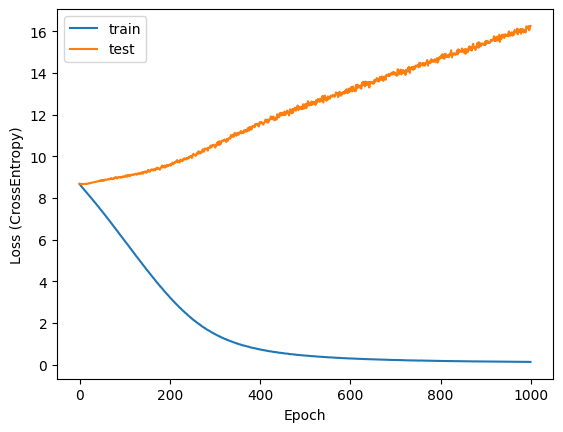

In [28]:
plt.plot(loss_list, label='train')
plt.plot(loss_list_val, label='test')
plt.ylabel('Loss (CrossEntropy)')
plt.xlabel('Epoch')
plt.legend()

In [17]:
model(xbt, generate=False).device

device(type='cuda', index=0)

In [18]:
[id_to_pos_dict[id_] for id_ in xbt[0, :1].detach().cpu().numpy()], xbt[0, :1].detach().cpu().numpy()

(['VSYEYOFVOZZCQLVFSDFZQCZMTEKW'], array([4124]))

In [19]:
[id_to_pos_dict[id_] for id_ in ybt[0, :1].detach().cpu().numpy()], ybt[0, :1].detach().cpu().numpy()

(['VSYEYOFVQLVFOZZCSDFZQCZMTEKW'], array([4127]))

In [20]:
[id_to_pos_dict[id_] for id_ in xbt[0, 1:2].detach().cpu().numpy()], xbt[0, 1:2].detach().cpu().numpy()

(['VSYEYOFVQLVFOZZCSDFZQCZMTEKW'], array([4127]))

In [21]:
torch.argmax(model(xbt[0, :,], generate=False).view(-1, VOCAB_SIZE), dim=-1)[0]

tensor(4127, device='cuda:0')

In [ ]:
for i in range(1, MAX_SEQ_LEN+1):
    print(np.mean(
        F.cross_entropy(model(xb[:, :i], generate=False), yb[:, ])
    ))

In [144]:
[id_to_pos_dict[id_] for id_ in xb[0, :1].detach().cpu().numpy()], xb[0, :1].detach().cpu().numpy()

(['MBKLTEKWEYCFSDFZLOCAAJECYOFV'], array([2815]))

In [145]:
[id_to_pos_dict[id_] for id_ in yb[0, :1].detach().cpu().numpy()], yb[0, :1].detach().cpu().numpy()

(['VVQPAZWLLPMUPVPVMXRVAZGASYAO'], array([4201]))

In [146]:
[id_to_pos_dict[id_] for id_ in xb[0, 1:2].detach().cpu().numpy()], xb[0, 1:2].detach().cpu().numpy()

(['VVQPAZWLLPMUPVPVMXRVAZGASYAO'], array([4201]))

In [23]:
torch.argmax(model(xb[0,:].to(DEVICE), generate=False).view(-1, VOCAB_SIZE), dim=-1)

tensor([ 764,  747,  751,  812,  811,  810,  807,  797,  801,  800,  792,  782,
        1496, 1501, 1502, 1513], device='cuda:0')

In [25]:
torch.argmax(model(xb[0,:].to(DEVICE), generate=False).view(-1, VOCAB_SIZE), dim=-1)

tensor([ 764,  747,  751,  812,  811,  810,  807,  797,  801,  800,  792,  782,
        1496, 1501, 1502, 1513], device='cuda:0')

In [26]:
[id_to_pos_dict[id_] for id_ in yb[0, :5].detach().cpu().numpy()], yb[0, :5].detach().cpu().numpy()

(['ECUEFEXXVTWRZTESYRGTGRZHWGOX',
  'ECUEFEXXGRZHVTWRZTESYRGTWGOX',
  'ECUEFEXXGRZHZTESVTWRYRGTWGOX',
  'ECUEGRZHFEXXZTESVTWRYRGTWGOX',
  'ECUEGRZHFEXXZTESVTWRYRGTCMWF'],
 array([752, 747, 751, 812, 811]))

In [223]:
F.cross_entropy(model(xb.to(DEVICE), generate=False).view(BATCH_SIZE*MAX_SEQ_LEN, VOCAB_SIZE), yb.to(DEVICE).view(BATCH_SIZE*MAX_SEQ_LEN))

tensor(0.1891, device='cuda:0', grad_fn=<NllLossBackward0>)

In [225]:
model(xb.to(DEVICE), generate=False).view(-1, VOCAB_SIZE).shape

torch.Size([256, 4955])

In [226]:
model(xb.to(DEVICE), generate=False).view(BATCH_SIZE*MAX_SEQ_LEN, VOCAB_SIZE).shape

torch.Size([256, 4955])

In [208]:
yb[0, :].to(DEVICE).view(MAX_SEQ_LEN).shape

torch.Size([8])

In [175]:
model(xb[0,:].to(DEVICE), generate=False).shape

torch.Size([1, 8, 4955])

In [197]:
model(xb[0,:].to(DEVICE), generate=False).view(MAX_SEQ_LEN, -1).shape

torch.Size([8, 4955])

In [176]:
VOCAB_SIZE

4955

In [164]:
xb[0,:]

tensor([4101,   57,  789, 4507, 1893, 2870, 1650, 2547])

In [81]:
ybt[0, :5]

tensor([1350,  487, 4617, 1647, 4815], device='cuda:0')

In [167]:
yb

tensor([[  57,  789, 4507,  ..., 1650, 2547,  358],
        [1215, 3391, 1728,  ..., 4315, 2838, 2355],
        [4759,  913, 4224,  ..., 4415, 2412, 1810],
        ...,
        [1405, 2793, 4171,  ...,  571, 1540, 2498],
        [ 721, 2274, 1858,  ..., 3751, 3015,  559],
        [3046, 2206, 1845,  ..., 4830, 2207, 3437]])

In [139]:
BATCH_SIZE*MAX_SEQ_LEN

4096

In [155]:
dataloader = custom_dataloader(
                dataset = train_tensor
                ,batch_size = BATCH_SIZE
                ,context_len = MAX_SEQ_LEN
                , device = DEVICE
                )
epoch_loss_list = []


for xb, yb in dataloader:
    break
    pass

In [156]:
xb

tensor([[4101,   57,  789,  ..., 2870, 1650, 2547],
        [  60, 1215, 3391,  ..., 4608, 4315, 2838],
        [2286, 4759,  913,  ..., 4722, 4415, 2412],
        ...,
        [3305, 1405, 2793,  ..., 2586,  571, 1540],
        [3778,  721, 2274,  ...,  102, 3751, 3015],
        [1494, 3046, 2206,  ..., 2944, 4830, 2207]])

In [157]:
id_to_pos_dict[659]

'DJPTTTHFIETMJUHOXTYHSIGZLCBX'

In [85]:
id_to_pos_dict[4815]

'YTTFGRZHARIMOGEACGVVUPCGECUE'

In [32]:
xbt[0, :5].detach().numpy()

array([4636, 3954, 4109, 1904, 4914])

In [87]:
model.embedding(xbt[0,:]).shape

torch.Size([16, 512])

In [94]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

def visualize_embeddings(model, vocab, device, context_len=50):
    # Supondo que o modelo já tenha sido treinado e os embeddings sejam armazenados no modelo
    embeddings = model.embedding.embedding.weight.detach().cpu().numpy()  # Acessando os embeddings do modelo
    
    # O vocab é o dicionário que mapeia os ids dos tokens para strings (ex: 'word1' -> id 1)
    # Vamos converter o vocab para uma lista de palavras
    vocab_list = [vocab[i] for i in range(len(vocab))]

    # Reduzindo a dimensionalidade dos embeddings para 2D com t-SNE
    tsne = TSNE(n_components=2, random_state=42)
    embeddings_2d = tsne.fit_transform(embeddings)

    # Plotando os embeddings 2D
    plt.figure(figsize=(12, 12))
    plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], color='blue', marker='o')

    # # Adicionando as palavras no gráfico
    # for i, word in enumerate(vocab_list):
    #     plt.annotate(word, (embeddings_2d[i, 0], embeddings_2d[i, 1]), fontsize=8)

    plt.title("Visualização dos Embeddings (t-SNE)")
    plt.show()

# Exemplo de uso:
# vocab = ['word1', 'word2', 'word3', ...]  # Lista de palavras do vocabulário
# visualize_embeddings(model, vocab, device)


In [95]:
vocab = [id_to_pos_dict[id_] for id_ in range(VOCAB_SIZE)]

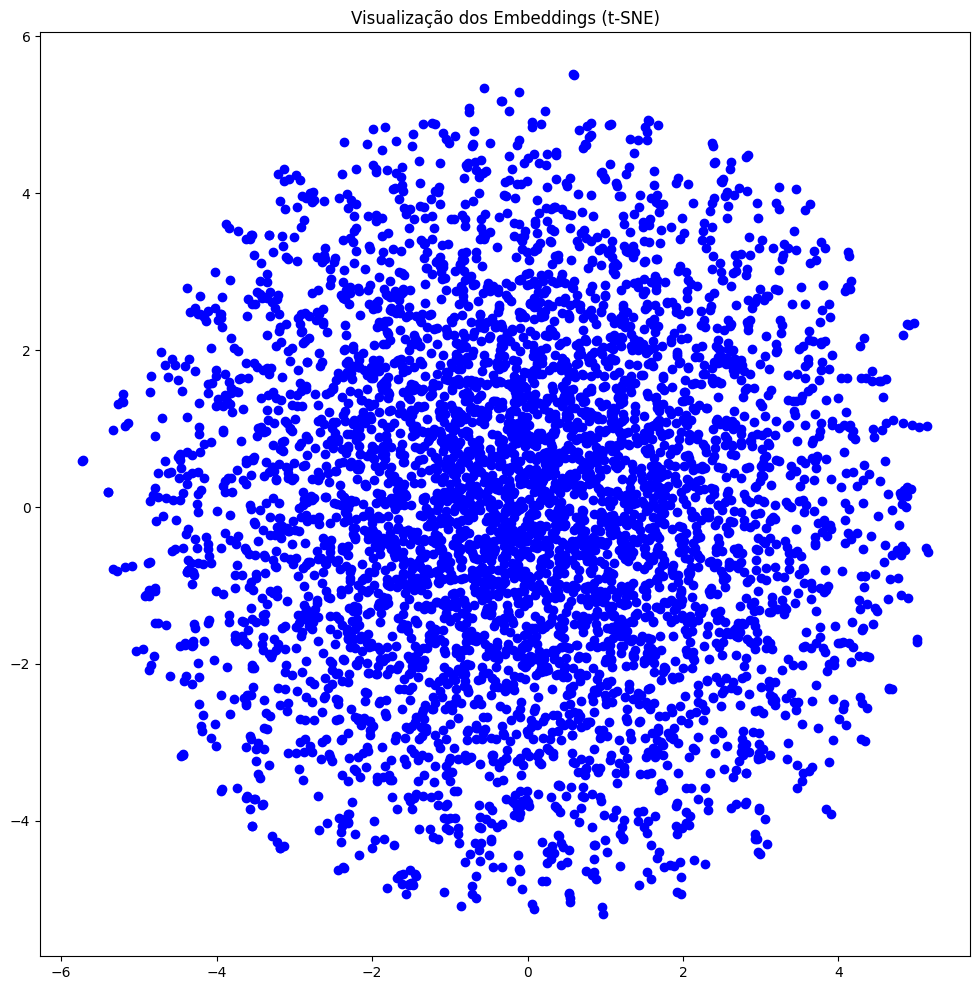

In [96]:
visualize_embeddings(model, vocab, DEVICE)

'AJECLQVLMBKLMSSOSZHZYBKOLOCA'

In [24]:
resultado = interpretar_predicoes(model(xbt, generate=False), ybt, id_to_pos_dict)
for linha in resultado:
    print(linha)

TypeError: unhashable type: 'list'

In [31]:
model(xb, generate=False)[0, :, :].shape

: 

(array([1., 1., 0., 0., 1., 1., 0., 1., 2., 1.]),
 array([ 118. ,  536.7,  955.4, 1374.1, 1792.8, 2211.5, 2630.2, 3048.9,
        3467.6, 3886.3, 4305. ]),
 <BarContainer object of 10 artists>)

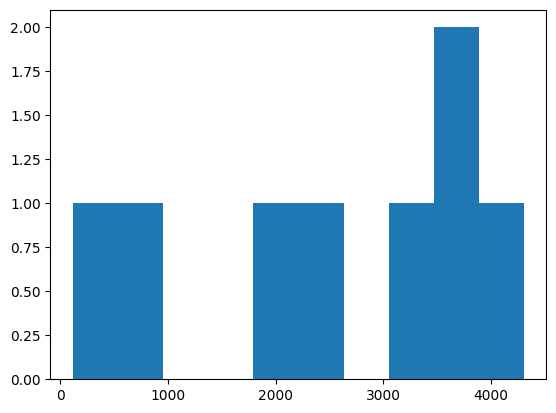

In [119]:
plt.hist(yb[0,:])

(array([2., 1., 1., 1., 0., 1., 0., 0., 0., 2.]),
 array([ 464. ,  831.8, 1199.6, 1567.4, 1935.2, 2303. , 2670.8, 3038.6,
        3406.4, 3774.2, 4142. ]),
 <BarContainer object of 10 artists>)

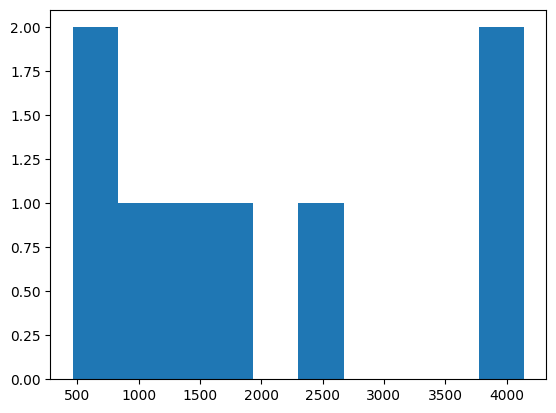

In [120]:
plt.hist(ybt[0,:])

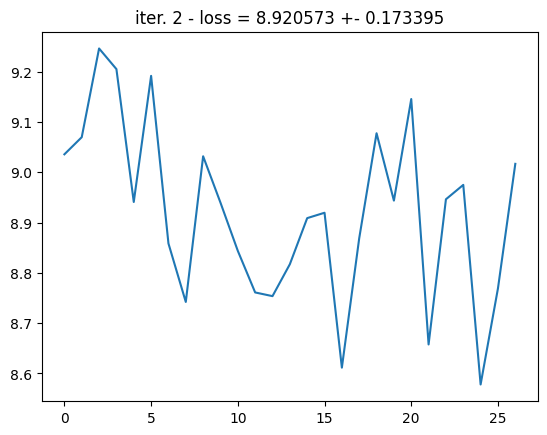

In [94]:
plt.plot(val_loss_list)
plt.title(f"iter. {epoch} - loss = {np.mean(val_loss_list):4f} +- {np.std(val_loss_list):4f}")
plt.show()

In [13]:
ybt.shape

torch.Size([32, 64])